In [ ]:
import dotenv 

In [ ]:
import os
from dotenv import load_dotenv
load_dotenv()

In [ ]:

os.environ['GROQ_API_KEY']=os.getenv('GROQ_API_KEY')

In [ ]:

os.environ['TAVILY_API_KEY']=os.getenv('TAVILY_API_KEY')

In [ ]:
from langchain.chat_models import init_chat_model
llm= init_chat_model(model="openai/gpt-oss-120b",model_provider='groq')

In [ ]:
from langchain_community.tools import ArxivQueryRun,WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper,ArxivAPIWrapper

In [ ]:
api_wrapper_arxiv= ArxivAPIWrapper(top_k_results=2,doc_content_chars_max=500)
arxiv=ArxivQueryRun(api_wrapper=api_wrapper_arxiv)

print(arxiv.name)

In [ ]:
import arxiv
from langchain_community.utilities import ArxivAPIWrapper
from langchain_community.tools import ArxivQueryRun

# Fix for AttributeError: 'Search' object has no attribute 'results'
arxiv.Search.results = lambda self, *args, **kwargs: arxiv.Client().results(self, *args, **kwargs)

# Tool initialize karein
arxiv_tool = ArxivQueryRun(api_wrapper=ArxivAPIWrapper())

# Search run karein
response = arxiv_tool.invoke("Attention is all you need")
print(response)

In [ ]:
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper
from langchain_community.tools import WikipediaQueryRun, ArxivQueryRun

# 1. Wikipedia Tool
api_wrapper_wiki = WikipediaAPIWrapper(top_k_results=2, doc_content_chars_max=500)
wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)


# Check names
print(wiki.name)   # Output: wikipedia


In [ ]:

from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.tools import WikipediaQueryRun

api_wrapper_wiki = WikipediaAPIWrapper(
    top_k_results=2,
    doc_content_chars_max=500)

wiki = WikipediaQueryRun(
    api_wrapper=api_wrapper_wiki)

result = wiki.invoke("What is Deep Learning?")

print(result)

In [ ]:
# tavily tool

In [ ]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily= TavilySearchResults()

In [ ]:
tavily.invoke('provide recent ai news nov 2026')

In [ ]:
# combine all tool in list

In [ ]:
tool=[arxiv_tool,wiki,tavily]

In [ ]:
from langchain.messages import AIMessage,HumanMessage,SystemMessage, AnyMessage

In [ ]:
llm_with_tool=llm.bind_tools(tool)

llm_with_tool.invoke([HumanMessage(content='what is llm model')])

In [ ]:
from typing_extensions import TypedDict
from typing import Annotated
from langgraph.graph.message import add_messages

In [ ]:
from typing import Annotated
from typing_extensions import TypedDict
from langchain.messages import AnyMessage
from langgraph.graph.message import add_messages

class State(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

In [ ]:
from langgraph.graph import StateGraph,END,START

from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition


In [52]:
#Node 
def tool_call_llm(state:State):
    return {'messages':[llm_with_tool.invoke(state['messages'])]}

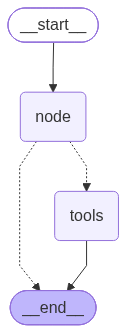

In [59]:
graph = StateGraph(State)


graph.add_node('node', tool_call_llm)
graph.add_node('tools', ToolNode(tool))


graph.add_edge(START, 'node')

graph.add_conditional_edges('node', tools_condition)


graph.add_edge('tools', END)


graph.compile()

In [60]:
graph.compile().invoke({'messages':HumanMessage(content='what is machine learning')})

{'messages': [HumanMessage(content='what is machine learning', additional_kwargs={}, response_metadata={}, id='a7345fd6-22d2-42d6-824b-af8108781130'),
  AIMessage(content='**Machine learning (ML)** is a sub‑field of artificial intelligence (AI) that focuses on developing algorithms and statistical models that enable computers to **learn from data** and improve their performance on a specific task without being explicitly programmed for every possible scenario.\n\n### Core Idea\n- **Data → Experience → Knowledge**: By exposing an algorithm to examples (data), the system extracts patterns, builds a model, and uses that model to make predictions or decisions on new, unseen data.\n- **Optimization**: Learning is usually framed as an optimization problem—adjusting model parameters to minimize a loss (error) on the training data.\n\n### Typical Workflow\n1. **Collect Data** – Gather labeled (supervised) or unlabeled (unsupervised) examples.\n2. **Preprocess** – Clean, normalize, and possibly

In [62]:
for m in graph.compile().invoke({'messages':HumanMessage(content='what is machine learning and tell me which tool are used in find answer')})['messages']:
    m.pretty_print()

================================ Human Message =================================

what is machine learning and tell me which tool are used in find answer
================================== Ai Message ==================================

**Machine Learning – A Quick Overview**

Machine Learning (ML) is a sub‑field of artificial intelligence that gives computers the ability to learn from data — that is, to automatically improve their performance on a task without being explicitly programmed for every possible situation. In practice, an ML system builds a statistical model from examples (training data) and then uses that model to make predictions or decisions on new, unseen data.

| **Key Concepts** | **Explanation** |
|------------------|-----------------|
| **Data** | The raw material (numbers, text, images, etc.) that the algorithm learns from. |
| **Model** | A mathematical representation (e.g., a set of weights in a neural network) that captures patterns in the data. |
| **Training** 